# Tugas P9 — Klasifikasi Logistic Regression
### Prediksi Customer Churn pada Perusahaan Telekomunikasi

**Kelompok 1**
1. Muhammad Besttan Dhya Ulhaq — 2023018039
2. Ulul Hikam — 2023018037
3. Riski Intan Pertiwi — 2023018048
4. Pawarna — 2023018061

Notebook ini mereproduksi seluruh angka pada laporan. Jalankan dari atas ke bawah
(menu *Run All*) atau buka di Google Colab setelah mengunggah `data/Telco-Customer-Churn.csv`.

## 1. Persiapan

In [1]:
%matplotlib inline
import sys, os
from pathlib import Path

# pastikan root proyek ada di sys.path (agar `import src` bekerja dari folder notebook/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
SEED = 42

## 2. Memuat Data

Dataset: **Telco Customer Churn** (IBM Sample Data Sets). Jika berkas lokal tidak ditemukan,
data diunduh otomatis dari repositori publik.

In [2]:
from src import data as datamod

df_raw = datamod.load_raw()
print("Ukuran data :", df_raw.shape)
df_raw.head()

Ukuran data : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Pembersihan: TotalCharges -> numerik, nilai kosong -> 0, target -> 0/1
df = datamod.clean(df_raw)
print("Jumlah nilai kosong TotalCharges:",
      pd.to_numeric(df_raw["TotalCharges"], errors="coerce").isna().sum())
print("Churn rate: %.2f%%" % (df["Churn"].mean() * 100))
df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].describe().round(2)

Jumlah nilai kosong TotalCharges: 11
Churn rate: 26.54%


,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,0.27
std,24.56,30.09,2266.79,0.44
min,0.00,18.25,0.00,0.00
25%,9.00,35.50,398.55,0.00
50%,29.00,70.35,1394.55,0.00
75%,55.00,89.85,3786.60,1.00
max,72.00,118.75,8684.80,1.00


## 3. Analisis Data Eksploratif

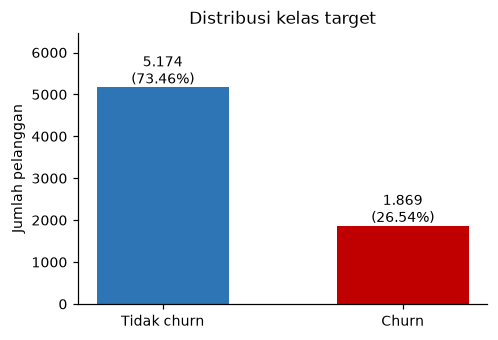

In [4]:
counts = df["Churn"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(4.8, 3.2))
bars = ax.bar(["Tidak churn", "Churn"], counts.values, color=["#2E75B6", "#C00000"], width=0.55)
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 90,
            f"{v:,}\n({v/len(df)*100:.2f}%)".replace(",", "."), ha="center", fontsize=9)
ax.set_ylabel("Jumlah pelanggan"); ax.set_title("Distribusi kelas target")
ax.set_ylim(0, counts.max() * 1.25)
plt.show()

In [5]:
churn_kontrak = (df.groupby("Contract")["Churn"]
                   .agg(jumlah="size", churn="sum"))
churn_kontrak["churn_rate_%"] = (churn_kontrak["churn"] / churn_kontrak["jumlah"] * 100).round(2)
churn_kontrak.loc[["Month-to-month", "One year", "Two year"]]

,jumlah,churn,churn_rate_%
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


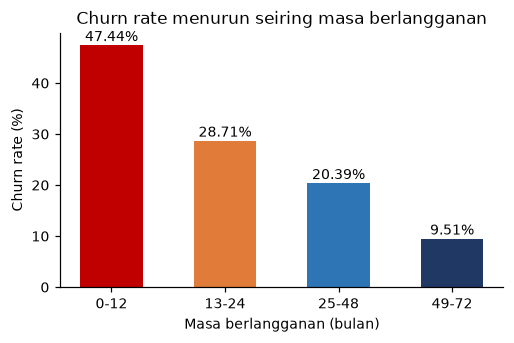

In [6]:
bins = [0, 12, 24, 48, 72]
label = ["0-12", "13-24", "25-48", "49-72"]
grup = pd.cut(df["tenure"], bins=bins, labels=label, include_lowest=True)
churn_tenure = df.groupby(grup, observed=True)["Churn"].agg(jumlah="size", churn="sum")
churn_tenure["churn_rate_%"] = (churn_tenure["churn"] / churn_tenure["jumlah"] * 100).round(2)

fig, ax = plt.subplots(figsize=(5.2, 3.0))
ax.bar(label, churn_tenure["churn_rate_%"], color=["#C00000", "#E07B39", "#2E75B6", "#1F3864"], width=0.55)
for i, v in enumerate(churn_tenure["churn_rate_%"]):
    ax.text(i, v + 0.8, f"{v:.2f}%", ha="center", fontsize=9)
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Masa berlangganan (bulan)")
ax.set_title("Churn rate menurun seiring masa berlangganan")
plt.show()

**Temuan EDA.** Pelanggan kontrak bulanan memiliki churn rate jauh lebih tinggi daripada
kontrak tahunan, dan risiko terkonsentrasi pada 12 bulan pertama. Kedua pola ini menjadi
hipotesis yang akan diuji oleh model.

## 4. Praproses dan Pembagian Data

In [7]:
NUMERIK = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
KATEGORI = [c for c in df.columns if c not in NUMERIK + ["customerID", "Churn"]]

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIK),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), KATEGORI),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print("Data latih :", X_train.shape, "| churn:", round(y_train.mean()*100, 2), "%")
print("Data uji   :", X_test.shape, "| churn:", round(y_test.mean()*100, 2), "%")

Data latih : (5634, 19) | churn: 26.54 %
Data uji   : (1409, 19) | churn: 26.54 %


## 5. Pelatihan Model

In [8]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs", random_state=SEED)),
])
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print("Konvergen dalam", model.named_steps["classifier"].n_iter_[0], "iterasi")

Konvergen dalam 49 iterasi


## 6. Evaluasi

In [9]:
hasil = {
    "Accuracy" : accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall"   : recall_score(y_test, pred),
    "F1-score" : f1_score(y_test, pred),
    "ROC-AUC"  : roc_auc_score(y_test, proba),
}
pd.DataFrame({"Nilai": [f"{v*100:.2f}%" if k != "ROC-AUC" else f"{v:.4f}"
                        for k, v in hasil.items()]}, index=hasil.keys())

,Nilai
Accuracy,80.70%
Precision,66.04%
Recall,56.15%
F1-score,60.69%
ROC-AUC,0.8422


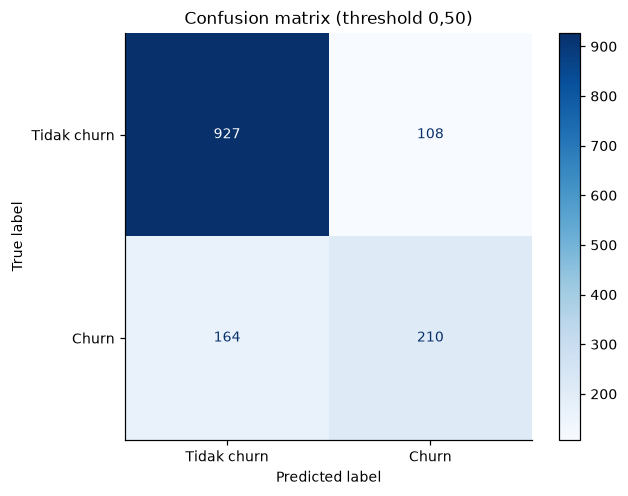

TN=927  FP=108  FN=164  TP=210
Baseline naif (semua 'tidak churn'): 73.46%


In [10]:
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["Tidak churn", "Churn"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (threshold 0,50)")
plt.show()
print("TN=%d  FP=%d  FN=%d  TP=%d" % (cm[0,0], cm[0,1], cm[1,0], cm[1,1]))
print("Baseline naif (semua 'tidak churn'): %.2f%%" % ((y_test == 0).mean() * 100))

### Threshold tuning

Pada konteks retensi, *false negative* (pelanggan churn yang lolos) lebih mahal daripada
*false positive* (promo salah sasaran). Karena itu ambang diturunkan untuk menaikkan recall.

In [11]:
rows = []
for t in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    p = (proba >= t).astype(int)
    rows.append([t, accuracy_score(y_test, p)*100, precision_score(y_test, p)*100,
                 recall_score(y_test, p)*100, f1_score(y_test, p)*100,
                 int(((p == 1) & (y_test == 1)).sum()),
                 int(((p == 0) & (y_test == 1)).sum())])
tabel = pd.DataFrame(rows, columns=["Threshold", "Accuracy", "Precision", "Recall", "F1",
                                    "Churn tertangkap", "Churn terlewat"]).round(2)
tabel

,Threshold,Accuracy,Precision,Recall,F1,Churn tertangkap,Churn terlewat
0,0.20,70.26,46.72,85.56,60.43,320,54
1,0.25,73.31,49.84,81.02,61.71,303,71
2,0.30,74.95,51.93,75.40,61.50,282,92
3,0.35,76.51,54.41,70.86,61.56,265,109
4,0.40,77.86,57.08,66.84,61.58,250,124
5,0.45,78.92,60.05,61.50,60.77,230,144
6,0.50,80.70,66.04,56.15,60.69,210,164
7,0.55,79.84,67.72,45.99,54.78,172,202
8,0.60,79.91,71.77,40.11,51.46,150,224


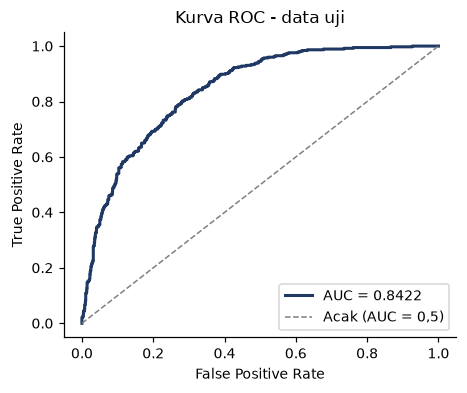

In [12]:
fpr, tpr, _ = roc_curve(y_test, proba)
fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.plot(fpr, tpr, color="#1F3864", lw=2, label=f"AUC = {roc_auc_score(y_test, proba):.4f}")
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1, label="Acak (AUC = 0,5)")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("Kurva ROC - data uji"); ax.legend(loc="lower right")
plt.show()

In [13]:
cv = cross_val_score(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                     scoring="roc_auc", n_jobs=-1)
print("AUC tiap fold :", np.round(cv, 4))
print("Rata-rata     : %.4f +/- %.4f" % (cv.mean(), cv.std()))

AUC tiap fold : [0.8546 0.8454 0.8636 0.8253 0.8364]
Rata-rata     : 0.8451 +/- 0.0134


## 7. Interpretasi Koefisien

In [14]:
nama = [n.split("__", 1)[-1] for n in model.named_steps["preprocessor"].get_feature_names_out()]
koef = model.named_steps["classifier"].coef_[0]

tabel_koef = (pd.DataFrame({"fitur": nama, "koefisien": koef.round(3),
                            "odds_ratio": np.exp(koef).round(3)})
              .sort_values("koefisien").reset_index(drop=True))
tabel_koef.head(6)

,fitur,koefisien,odds_ratio
0,Contract_Two year,-1.326,0.265
1,tenure,-1.250,0.286
2,Contract_One year,-0.687,0.503
3,PhoneService_Yes,-0.505,0.603
4,MonthlyCharges,-0.471,0.625
5,OnlineSecurity_Yes,-0.350,0.705


In [15]:
tabel_koef.tail(6).iloc[::-1]

,fitur,koefisien,odds_ratio
29,InternetService_Fiber optic,1.182,3.262
28,TotalCharges,0.523,1.687
27,PaymentMethod_Electronic check,0.384,1.468
26,StreamingTV_Yes,0.378,1.459
25,StreamingMovies_Yes,0.376,1.457
24,PaperlessBilling_Yes,0.371,1.450


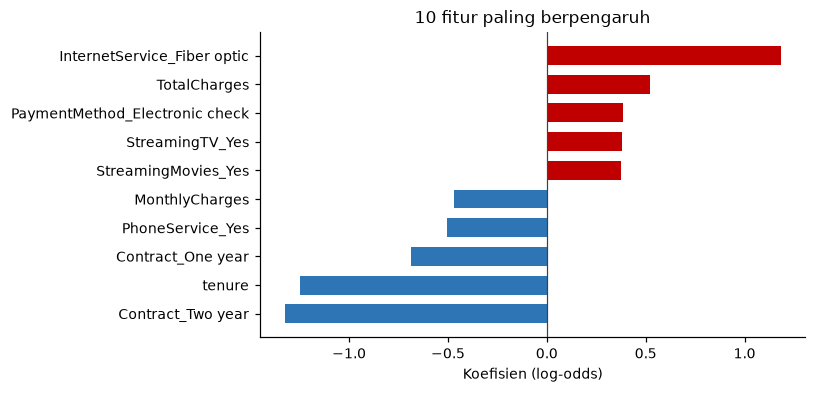

In [16]:
subset = tabel_koef.reindex(tabel_koef["koefisien"].abs().sort_values(ascending=False).index).head(10)
subset = subset.sort_values("koefisien")
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.barh(subset["fitur"], subset["koefisien"],
        color=["#C00000" if v > 0 else "#2E75B6" for v in subset["koefisien"]], height=0.66)
ax.axvline(0, color="#404040", lw=0.8)
ax.set_xlabel("Koefisien (log-odds)"); ax.set_title("10 fitur paling berpengaruh")
plt.show()

## 8. Kesimpulan Singkat

1. Model regresi logistik mencapai **ROC-AUC 0,8422** dan accuracy **80,70%** pada data uji,
   di atas baseline naif 73,46%.
2. Tipe kontrak, masa berlangganan, dan jenis layanan internet adalah faktor dominan.
3. Ambang 0,30 menaikkan recall dari 56,15% menjadi 75,40%, lebih sesuai untuk program retensi.
4. Terdapat indikasi multikolinearitas antara `tenure`, `TotalCharges`, dan `MonthlyCharges`
   yang membuat koefisien tagihan bulanan bertanda negatif.

## 9. Uji Coba Prediksi Pelanggan Baru

Cell di bawah memuat model yang sudah disimpan oleh `run_pipeline.py` (jika ada) lalu memberi
skor pada tiga profil pelanggan.

In [17]:
import joblib
from src import config

if config.MODEL_FILE.exists():
    model_disk = joblib.load(config.MODEL_FILE)
else:
    model_disk = model  # fallback: model yang baru dilatih di notebook

contoh = pd.DataFrame([
    dict(gender="Female", SeniorCitizen=0, Partner="No", Dependents="No", tenure=3,
         PhoneService="Yes", MultipleLines="Yes", InternetService="Fiber optic",
         OnlineSecurity="No", OnlineBackup="No", DeviceProtection="No", TechSupport="No",
         StreamingTV="Yes", StreamingMovies="Yes", Contract="Month-to-month",
         PaperlessBilling="Yes", PaymentMethod="Electronic check",
         MonthlyCharges=95.5, TotalCharges=286.5),
    dict(gender="Male", SeniorCitizen=0, Partner="Yes", Dependents="Yes", tenure=60,
         PhoneService="Yes", MultipleLines="No", InternetService="DSL",
         OnlineSecurity="Yes", OnlineBackup="Yes", DeviceProtection="Yes", TechSupport="Yes",
         StreamingTV="No", StreamingMovies="No", Contract="Two year",
         PaperlessBilling="No", PaymentMethod="Credit card (automatic)",
         MonthlyCharges=55.0, TotalCharges=3300.0),
])

contoh["probabilitas_churn"] = model_disk.predict_proba(contoh[X.columns])[:, 1].round(4)
contoh[["Contract", "tenure", "MonthlyCharges", "probabilitas_churn"]]

,Contract,tenure,MonthlyCharges,probabilitas_churn
0,Month-to-month,3,95.5,0.8204
1,Two year,60,55.0,0.0047
